In [1]:
import numpy as np
import os, random
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torch.nn.functional as F
import torchvision.models as models
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import random_split
import matplotlib.pyplot as plt
import pickle

from my_utils import *

random.seed(42)

my_yellow = '#D0E000'
my_red = '#A02000'
my_grey = '#303730'
my_blue = '#0020A0'



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


data_dir = "/home/kia/Desktop/PoD/NNDL/Cars-classification-and-verification/data/CompCars/data/"
image_root = os.path.join(data_dir, "image")
label_root = os.path.join(data_dir, "label")



models_dir = "/home/kia/Desktop/PoD/NNDL/models/"


Using device: cuda


### Data Loader

In [6]:
dataset = SiameseDatasetBBox(image_root=image_root, label_root=label_root, same_view=True, mode="model")

train_dataset, val_dataset, test_dataset = split_by_labels(dataset, label_type="model", ratios=(0.8,0.1,0.1))

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=368, shuffle=True, num_workers=16)
val_loader   = DataLoader(val_dataset, batch_size=368, shuffle=False, num_workers=8)
test_loader  = DataLoader(test_dataset, batch_size=368, shuffle=False, num_workers=8)


In [ ]:
# main training loop

history = []
epoch = 0
svs = [0.]

# model = SiameseNet(embedding_dim=256, pretrained=False, freeze_backbone=False).to(device)
save_path = "/home/kia/Desktop/PoD/NNDL/models/siamese_contrastive_RN18_256_128x128_SV0_p2.pth"

for sv in svs:
    dataset = SiameseDatasetBBox(image_root=image_root, label_root=label_root, same_view=sv, mode="model")
    train_dataset, val_dataset, test_dataset = split_by_labels(dataset, label_type="model", ratios=(0.8,0.1,0.1))
    for bs in [4, 368, 32, 368]:
        train_loader = DataLoader(train_dataset, batch_size=bs, shuffle=True, num_workers=16)
        val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=16)
        for mar in [1]:
            for lr in [1e-4, 1e-5]:
                criterion = ContrastiveLoss(margin=mar)
                optimizer = optim.Adam(
                    filter(lambda p: p.requires_grad, model.parameters()),
                    lr=lr, weight_decay=1e-5
                )

                train_losses, val_losses, val_accs = train(model, train_loader, criterion, optimizer, val_loader= val_loader, device = device, epochs=6)
                history.append((sv, bs, mar, lr, train_losses, val_losses, val_accs))
                print(f"sv: {sv}, bs: {bs}, margin: {mar}, lr: {lr}")
                print("-"*50)
                epoch += 5


torch.save({
    "epoch": epoch,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "embedding_dim": model.head[0].out_features,
    "backbone": "resnet18",
    "mode": dataset.mode,
    "same_view": dataset.same_view
}, save_path)

with open(os.path.join(models_dir, "training_history_SV0_p2.pkl"), "wb") as f:
    pickle.dump(history, f)


Epoch 1/6 | Train Loss: 0.1063 | Val Loss: 0.12700272028385792 | Val Acc: 0.8409090909090909
Epoch 2/6 | Train Loss: 0.1047 | Val Loss: 0.12141745616355702 | Val Acc: 0.8483606557377049
Epoch 3/6 | Train Loss: 0.1023 | Val Loss: 0.12616834779521213 | Val Acc: 0.8442622950819673
Epoch 4/6 | Train Loss: 0.1001 | Val Loss: 0.12738411683705808 | Val Acc: 0.8379284649776453
Epoch 5/6 | Train Loss: 0.1006 | Val Loss: 0.12742981396826475 | Val Acc: 0.8353204172876304
Epoch 6/6 | Train Loss: 0.0989 | Val Loss: 0.13232911670172445 | Val Acc: 0.8383010432190761
sv: 0.0, bs: 4, margin: 1, lr: 0.0001
--------------------------------------------------
Epoch 1/6 | Train Loss: 0.0938 | Val Loss: 0.12280907480798428 | Val Acc: 0.853204172876304
Epoch 2/6 | Train Loss: 0.0899 | Val Loss: 0.11847951481932144 | Val Acc: 0.8573025335320418
Epoch 3/6 | Train Loss: 0.0896 | Val Loss: 0.1267163305808464 | Val Acc: 0.8405365126676602
Epoch 4/6 | Train Loss: 0.0886 | Val Loss: 0.12604945569386602 | Val Acc: 0.

In [3]:
models_dir = "/home/kia/Desktop/PoD/NNDL/models/"

h1 = pickle.load(open(os.path.join(models_dir, "training_history_SV0.pkl"), "rb"))
h2 = pickle.load(open(os.path.join(models_dir, "training_history_SV0_p2.pkl"), "rb"))

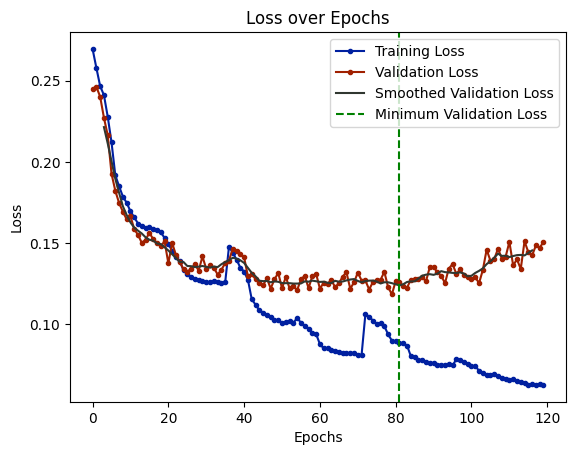

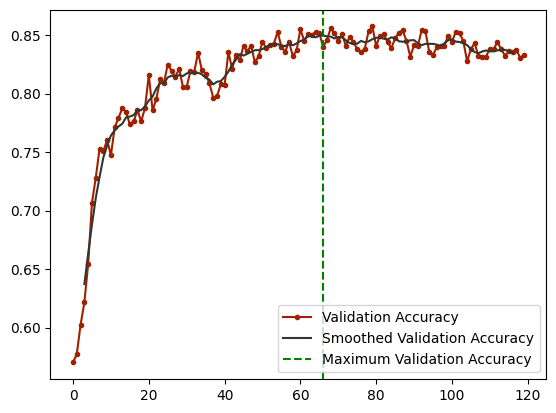

In [18]:
trl1 = [h1[i][4] for i in range(len(h1))]
vll1 = [h1[i][5] for i in range(len(h1))]
vla1 = [h1[i][6] for i in range(len(h1))]

trl2 = [h2[i][4] for i in range(len(h2))]
vll2 = [h2[i][5] for i in range(len(h2))]
vla2 = [h2[i][6] for i in range(len(h2))]

tr_loss = np.array(trl1 + trl2).flatten()
vl_loss = np.array(vll1 + vll2).flatten()
vl_acc = np.array(vla1 + vla2).flatten()

epochs_axis = range(len(tr_loss))


plt.plot(epochs_axis, tr_loss, color=my_blue, label="Training Loss", marker='.')
plt.plot(epochs_axis, vl_loss, color=my_red, label="Validation Loss", marker='.')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss over Epochs")
vll_smooth = np.convolve(vl_loss, np.array(np.ones(7))/7, mode='valid')
min_val_loss = np.where(vll_smooth == min(vll_smooth))[0][0]+3
plt.plot(epochs_axis[3:-3], vll_smooth, color=my_grey, label='Smoothed Validation Loss')
plt.axvline(min_val_loss, color='g', linestyle='--', label='Minimum Validation Loss')
plt.legend()
plt.show()


plt.plot(epochs_axis, vl_acc, label="Validation Accuracy", color=my_red, marker='.')
vla_smooth = np.convolve(vl_acc, np.array(np.ones(7))/7, mode='valid')
max_val_acc = np.where(vla_smooth == max(vla_smooth))[0][0]+3
plt.plot(epochs_axis[3:-3], vla_smooth, color=my_grey, label='Smoothed Validation Accuracy', ls = 'solid')
plt.axvline(max_val_acc, color='g', linestyle='--', label='Maximum Validation Accuracy')
plt.legend()
plt.show()


Loading model from /home/kia/Desktop/PoD/NNDL/models/siamese_contrastive_RN18_256_128x128_SV0.pth


/home/kia/Desktop/PoD/NNDL/Cars-classification-and-verification/my_utils.py:461: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(load_path, map_locatio

Loading model from /home/kia/Desktop/PoD/NNDL/models/siamese_contrastive_RN18_256_128x128_SV0_p2.pth
Pos: n=12509, mean=0.3275, std=0.2268
Neg: n=12619, mean=1.0059, std=0.3924
ROC AUC: 0.9191
Best threshold=0.6354, Best accuracy=0.8509
Best recall=0.9006


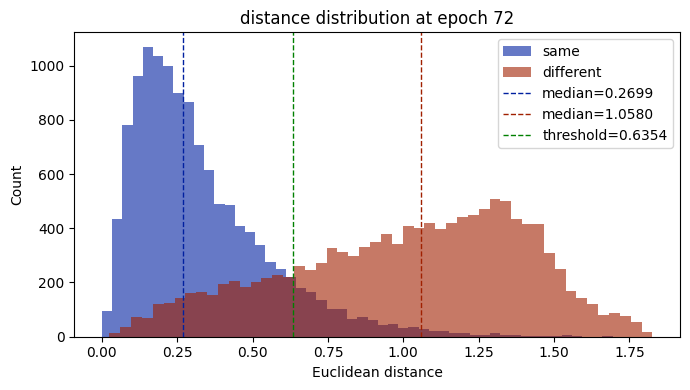

distance between medians: 0.7881 

Pos: n=12624, mean=0.3664, std=0.2793
Neg: n=12504, mean=1.1651, std=0.4652
ROC AUC: 0.9157
Best threshold=0.6604, Best accuracy=0.8477
Best recall=0.8666


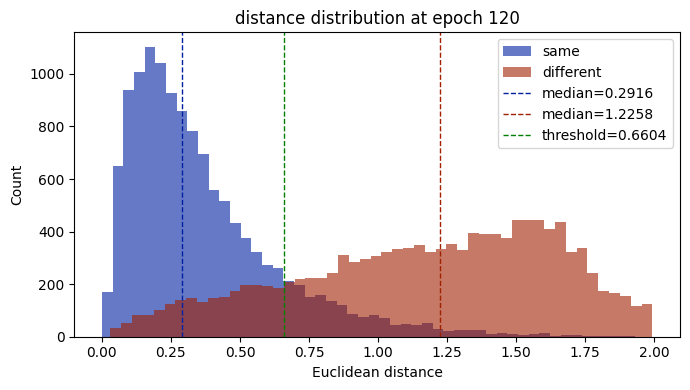

distance between medians: 0.9342 



In [7]:
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=8)
epoch72 = "/home/kia/Desktop/PoD/NNDL/models/siamese_contrastive_RN18_256_128x128_SV0.pth"
epoch120 = "/home/kia/Desktop/PoD/NNDL/models/siamese_contrastive_RN18_256_128x128_SV0_p2.pth"
model72, checkpoint72 = load_model(load_path=epoch72, resume_training=False)
model120, checkpoint120 = load_model(load_path=epoch120, resume_training=False)
t72 = plot_distance_distribution(model72, test_loader, device, bins=50, title="distance distribution at epoch 72")
t120 = plot_distance_distribution(model120, test_loader, device, bins=50, title="distance distribution at epoch 120")